# 03 – Model Comparison

This notebook compares the logistic regression baseline from 02_baseline.ipynb with two learned models: kNN and gradient boosting.

Data cleaning, train/test split, 5 folds and metrics are the same as in notebook 02, so all models are compared on the same evidence. The test set is still not used.

## 1. Load, clean and split (same as 02)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold

df = pd.read_csv("../data/raw/bank-additional-full.csv", sep=";")
df = df.drop_duplicates()             #12 exact duplicates
df = df.drop(columns="duration")      #known only after the call -> leakage

X = df.drop(columns="y")
y = (df["y"] == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (32940, 19) Test: (8236, 19)


## 2. Two preprocessing pipelines

The models need different preprocessing -> separate pipelines:

- Logistic regression and kNN: StandardScaler + OneHotEncoder (same as 02). kNN measures distances, scaling a feature with large numbers would dominate the distance.
- Gradient boosting: OneHotEncoder only. Trees split on one feature at a time, scale of a number does not change the result -> numbers are passed through unchanged.

Both fitted on training folds only.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

prep_scaled = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

prep_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),    #no scaling for trees
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

## 3. Metrics (same as 02)

F1 is the main metric; ROC-AUC, precision, recall and accuracy are secondary.

In [3]:
from sklearn.metrics import make_scorer, precision_score

metrics = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "accuracy": "accuracy",
}

## 4. kNN

kNN predicts "yes" or "no" from most similar clients in the training data.

Tuned with GridSearchCV on the training folds, using the grid from the lecture:
- n_neighbors (k): how many neighbours vote. Small k -> flexible but noisy, large k -> smoother.
- weights: every neighbour counts the same (uniform) or closer neighbours count more (distance).
- p: distance type, 1 = Manhattan, 2 = Euclidean.

Best setting chosen by F1 (scoring="f1"). n_jobs=2 runs 2 fits at the same time (only speed, results are the same).

In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

knn = make_pipeline(prep_scaled, KNeighborsClassifier())

knn_grid = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 11, 21],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2],
}
knn_search = GridSearchCV(knn, knn_grid, cv=cv, scoring="f1", n_jobs=2)
knn_search.fit(X_train, y_train)

print("Best settings:", knn_search.best_params_)
print("Best mean F1:", round(knn_search.best_score_, 3))

Best settings: {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'uniform'}
Best mean F1: 0.381


Validation F1 against k (for best weights and p), with standard deviation over the 5 folds as error bars:

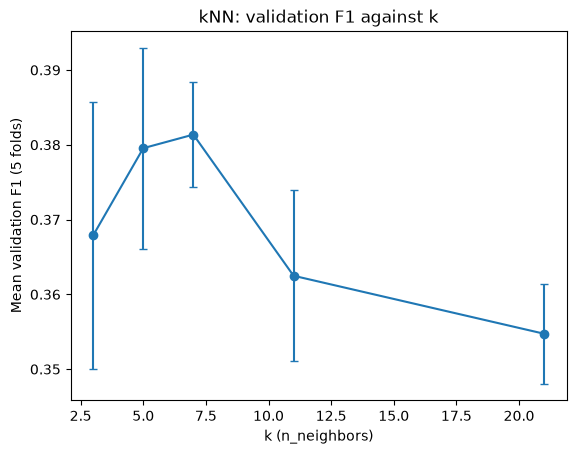

In [5]:
knn_res = pd.DataFrame(knn_search.cv_results_)
best = knn_search.best_params_
rows = knn_res[
    (knn_res["param_kneighborsclassifier__weights"] == best["kneighborsclassifier__weights"])
    & (knn_res["param_kneighborsclassifier__p"] == best["kneighborsclassifier__p"])
]

plt.errorbar(rows["param_kneighborsclassifier__n_neighbors"].astype(int),
             rows["mean_test_score"], yerr=rows["std_test_score"], marker="o", capsize=3)
plt.xlabel("k (n_neighbors)")
plt.ylabel("Mean validation F1 (5 folds)")
plt.title("kNN: validation F1 against k")
plt.savefig("../reports/figures/knn_f1_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()

- Best setting: k = 7, Euclidean distance (p = 2), uniform weights, F1 about 0.381.
- k = 3: large error bars -> very few neighbours -> prediction is noisy (high variance).
- k = 11 and 21: F1 drops -> in a bigger neighbourhood most neighbours are "no" (89% of clients, see target distribution in 01_data_audit), so the model predicts "yes" less often (higher bias).

## 5. Gradient boosting

Settings from the lecture example (n_estimators=200, learning_rate=0.05, max_depth=2, subsample=0.8). Only a small grid is searched around it (8 combinations), keep tuning proportionate:
- n_estimators: number of trees.
- learning_rate: how much each tree is allowed to correct.
- max_depth: size of each tree, depth 2-3 lets model combine 2-3 features (interactions).
- subsample=0.8 (fixed): each tree is trained on a random 80% of the rows, reduces overfitting.

In [6]:
from sklearn.ensemble import GradientBoostingClassifier

gb = make_pipeline(prep_tree, GradientBoostingClassifier(subsample=0.8, random_state=42))

gb_grid = {
    "gradientboostingclassifier__n_estimators": [100, 200],
    "gradientboostingclassifier__learning_rate": [0.05, 0.1],
    "gradientboostingclassifier__max_depth": [2, 3],
}
gb_search = GridSearchCV(gb, gb_grid, cv=cv, scoring="f1", n_jobs=2)
gb_search.fit(X_train, y_train)

print("Best settings:", gb_search.best_params_)
print("Best mean F1:", round(gb_search.best_score_, 3))

Best settings: {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__n_estimators': 200}
Best mean F1: 0.373


## 6. Results table

All rows use the same 5 training folds (mean ± standard deviation). Same loop as in 02, kNN and gradient boosting are added with their best settings from the grid search (best_estimator_). fit time is the mean training time per fold, predict time is the mean time to predict one validation fold (about 6,600 clients), in seconds.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

models = {
    "Dummy (most frequent)": make_pipeline(prep_scaled, DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_pipeline(prep_scaled, LogisticRegression(max_iter=1000)),
    "kNN (tuned)": knn_search.best_estimator_,
    "Gradient boosting (tuned)": gb_search.best_estimator_,
}
results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)
    results[name] = {m: f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}" for m in metrics}
    results[name]["fit time (s)"] = round(scores["fit_time"].mean(), 1)
    results[name]["predict time (s)"] = round(scores["score_time"].mean(), 1)

results_table = pd.DataFrame(results).T
results_table

,f1,roc_auc,precision,recall,accuracy,fit time (s),predict time (s)
Dummy (most frequent),0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.887 ± 0.000,0.2,0.1
Logistic regression,0.340 ± 0.004,0.790 ± 0.007,0.661 ± 0.025,0.229 ± 0.004,0.900 ± 0.001,0.9,0.1
kNN (tuned),0.381 ± 0.007,0.739 ± 0.007,0.568 ± 0.012,0.287 ± 0.010,0.895 ± 0.001,0.3,3.3
Gradient boosting (tuned),0.373 ± 0.007,0.798 ± 0.010,0.644 ± 0.017,0.262 ± 0.007,0.901 ± 0.001,26.8,0.2


- Both learned models beat dummy and the logistic regression baseline on: F1 0.381 (kNN) and 0.373 (gradient boosting) vs 0.340.
- F1 difference between kNN and gradient boosting (0.008) -> about one standard deviation -> not clear which is better.
- Gradient boosting has the best ROC-AUC (0.798) and a higher precision than kNN (0.644 vs 0.568): ranks clients better + gives fewer false. kNN has the lowest ROC-AUC (0.739)
- Recall is low for all models (0.23-0.29): at default threshold 0.5 most subscribers are missed.
- Cost: gradient boosting: the slowest to train. kNN trains quickly but has to compare every new client with all stored clients -> slowest to predict (3.3 s per validation fold vs 0.2 s for gradient boosting).
- The best gradient boosting setting is at the edge of the grid (largest learning_rate, max_depth and n_estimators), slightly larger values might improve it.

## 7. Confusion matrices

The three learned models side by side.

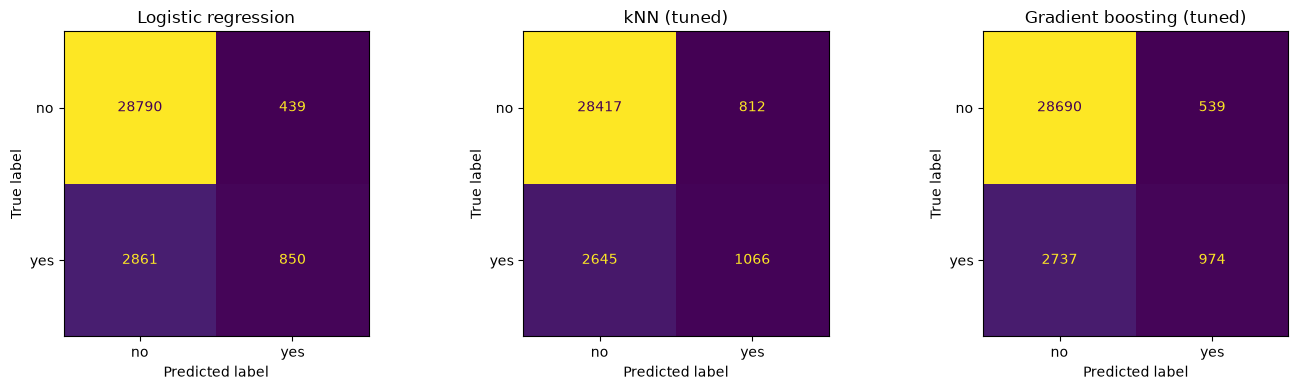

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

final_models = {
    "Logistic regression": models["Logistic regression"],
    "kNN (tuned)": knn_search.best_estimator_,
    "Gradient boosting (tuned)": gb_search.best_estimator_,
}

oof_pred = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, model) in zip(axes, final_models.items()):
    oof_pred[name] = cross_val_predict(model, X_train, y_train, cv=cv, n_jobs=2)
    ConfusionMatrixDisplay.from_predictions(
        y_train, oof_pred[name], display_labels=["no", "yes"], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

Of the 3,711 subscribers in the training set:
- logistic regression finds 850, gradient boosting 974 and kNN 1,066.
- kNN finds most subscribers, but has most false (812 vs 439 and 539).
- All three models miss more than 70% of the subscribers (2,645 to 2,861 false negatives).

## 8. Error analysis: which subscribers are missed

The main error of all models is missed subscribers (false negatives). share of actual subscribers that were found is split by three columns:
- poutcome: result of the previous campaign
- contact: cellular or telephone
- month: month of last contact

In [9]:
best_name = "kNN (tuned)"    #highest mean F1 in the results table

subscribers = X_train[y_train == 1].copy()
subscribers["found"] = oof_pred[best_name][y_train == 1]

for col in ["poutcome", "contact", "month"]:
    table = subscribers.groupby(col)["found"].agg(subscribers="size", recall="mean").round(3)
    display(table.sort_values("recall"))

,subscribers,recall
poutcome,,
nonexistent,2511,0.142
failure,478,0.203
success,722,0.848


,subscribers,recall
contact,,
telephone,623,0.114
cellular,3088,0.322


,subscribers,recall
month,,
may,704,0.124
jul,531,0.243
apr,425,0.245
jun,441,0.270
aug,533,0.272
nov,333,0.282
mar,215,0.479
oct,253,0.486
dec,73,0.507


Observed (kNN, out-of-fold):
- poutcome: if the previous campaign was a success, 85% of subscribers are found. For clients who were never contacted before (nonexistent, 2,511 of the 3,711 subscribers) only 14% are found.
- contact: 11% found for telephone vs 32% for cellular.
- month: May, worst month (12%), although it has the most subscribers (704). March, September, October and December sit around 48-62%, but these months have few calls.

Interpretation: the model finds subscribers mostly when there is a strong signal such as a previous success. New clients without a previous campaign, is where it does not perform as well as the other group.

## 9. Conclusion

Current best model: kNN (k = 7, uniform, Euclidean), highest F1 (0.381 ± 0.007). However, gradient boosting is within one standard deviation (0.373 ± 0.007) + has a better ROC-AUC (0.798 vs 0.739) and precision. Both beat logistic regression baseline (0.340) and the dummy (0.000).

Evidence: results table (same 5 folds and metrics for all models), confusion matrices and error analysis above.

Limitations:
- Recall is low (at most 0.29) at the default threshold of 0.5 -> most subscribers are missed.
- The models: tuned and scored on the same folds, tuned scores are a bit optimistic.
- Errors are concentrated in clients without a previous campaign, telephone contacts and May.
- All numbers are cross-validation estimates, test set has not been used so far.

Next steps:
- Choosing the final model between kNN and gradient boosting, considering F1, ROC-AUC, prediction time, and interpretability.
- Choosing the decision threshold on the training folds based on cost of a missed subscriber vs an unnecessary call.
- Extending the gradient boosting grid past its current edge.
- Evaluating the final model once on the test set.